# Comparing the Three-Body Model to Apollo 8

Apollo 8 (December 1968) was the first crewed mission to the Moon and was launched onto a **free-return trajectory**: if no further burns had been made after translunar injection (TLI), the spacecraft would have swung around the Moon and come straight back into Earth's atmosphere. That makes it the natural real-world check for the planar circular restricted three-body (CR3BP) model built in `FreeReturnTrajectory.ipynb`.

This notebook:

1. Records the Apollo 8 trajectory data from published NASA sources.
2. Compares the baseline initial conditions from `FreeReturnTrajectory.ipynb` against it.
3. Seeds the model with Apollo 8's *actual* TLI state, chooses the one unknown (the phase angle $\phi$) to match Apollo 8's predicted lunar closest approach, and checks what the model predicts for everything else.

**Sources**

- R. W. Orloff, *Apollo by the Numbers: A Statistical Reference*, NASA SP-2000-4029 — Apollo 8 Translunar, Lunar Orbit and Transearth phase tables, and mission narrative.
- NASA, *Apollo 8 Press Kit* (Release 68-208), 1968 — planned free-return entry time.
- NASA, *Apollo 8 Mission Report* (MSC-PA-R-69-1) — entry flight-path angle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Helpers.rk4 import rk4
from Helpers.constants import *

## Apollo 8 reference data

All values are copied from the sources above in their original units (n mi, ft/s, GET = ground elapsed time from liftoff) and converted to km, km/s and hours **after TLI** below.

A note on the lunar approach: the TLI burn was so accurate that, *with no further corrections*, Apollo 8 would have passed **458.1 n mi** above the Moon. The crew then made a midcourse correction at 011:00 GET to lower that to ~66 n mi for lunar orbit insertion (LOI). The 458.1 n mi value is the one that corresponds to a pure, uncorrected free return, which is what the model simulates.

In [2]:
NMI = 1.852 # km
FT = 0.3048e-3 # km

def get_to_hours(h, m, s):
    return h + m/60 + s/3600

GET_TLI = get_to_hours(2, 56, 5.51)

apollo8 = {
    # Translunar injection (Apollo by the Numbers, Translunar Phase table)
    'tli_alt': 187.221*NMI, # km
    'tli_speed': 35505.41*FT, # km/s, space fixed
    'tli_fpa': 7.897, # deg, space fixed

    # Closest approach to the Moon on the uncorrected free-return trajectory
    'perilune_alt_free_return': 458.1*NMI, # km
    # LOI ignition is just before pericynthion, so use it as the arrival time
    't_perilune': get_to_hours(69, 8, 20.4) - GET_TLI, # h after TLI
    'loi_alt': 75.6*NMI, # km

    # Entry interface, 400,000 ft (actual flight, after the lunar orbit stay)
    'ei_speed': 36221.1*FT, # km/s
    'ei_fpa': -6.50, # deg (Mission Report)
    # Press kit: on a pure free return, entry "at about 136 hours after liftoff"
    't_ei_free_return': 136 - GET_TLI, # h after TLI
}

# Points along the outbound coast for the distance-vs-time plot
# (hours after TLI, km from Earth's centre)
apollo8_earth_dist = np.array([
    [0, R_EARTH + 187.221*NMI],                                            # TLI
    [get_to_hours(3, 20, 59.3) - GET_TLI, R_EARTH + 3797.775*NMI],         # CSM / S-IVB separation
    [get_to_hours(10, 59, 59.2) - GET_TLI, R_EARTH + 52768.4*NMI],         # Midcourse correction 1
    [get_to_hours(55, 38, 40) - GET_TLI, 176250*NMI],                      # Crossed into Moon's gravity
])

# (hours after TLI, km from the Moon's centre)
apollo8_moon_dist = np.array([
    [get_to_hours(55, 38, 40) - GET_TLI, 33800*NMI],                      # Crossed into Moon's gravity
    [get_to_hours(60, 59, 55.9) - GET_TLI, R_MOON + 21064.5*NMI],         # Midcourse correction 2
    [apollo8['t_perilune'], R_MOON + apollo8['loi_alt']],                 # LOI ignition
])

for key, val in apollo8.items():
    print(f'{key:>26}: {val:10.3f}')

                   tli_alt:    346.733
                 tli_speed:     10.822
                   tli_fpa:      7.897
  perilune_alt_free_return:    848.401
                t_perilune:     66.204
                   loi_alt:    140.011
                  ei_speed:     11.040
                    ei_fpa:     -6.500
          t_ei_free_return:    133.065


## Model setup

Same equations of motion and baseline initial conditions as `FreeReturnTrajectory.ipynb`. The physical constants (masses, radii, $L$, $T$, $V$, $\mu$) are shared with that notebook through `Helpers/constants.py`.

In [3]:
def f_spacecraft(u, t):
    """The dynamics of the spacecraft: returns u_dot = f(u, t) for u = [x, y, v_x, v_y]."""

    r1 = np.sqrt((u[0] + MU)**2 + u[1]**2)
    r2 = np.sqrt((u[0] - 1 + MU)**2 + u[1]**2)

    return np.array([
        u[2],
        u[3],
        (1 - (1 - MU)/r1**3 - MU/r2**3)*u[0] + 2*u[3] + MU*(1 - MU)*(1/r2**3 - 1/r1**3),
        (1 - (1 - MU)/(r1**3) - MU/r2**3)*u[1] - 2*u[2]
    ])

The model state is in the rotating frame, but Apollo reports *space-fixed* (inertial, Earth-centred) speed and flight-path angle. With $\omega = 1$ in nondimensional units, the Earth-centred inertial velocity is

$$
\vec v_{in} = \vec v_{rot} + \vec\omega \times \vec r_E = \begin{bmatrix} v_x - y \\ v_y + (x + \mu) \end{bmatrix}
$$

and the flight-path angle is the angle of $\vec v_{in}$ above the local horizontal: $\gamma = \sin^{-1}\left(\frac{\vec r_E \cdot \vec v_{in}}{|\vec r_E| |\vec v_{in}|}\right)$.

In [4]:
def earth_dist(u):
    return np.hypot(u[..., 0] + MU, u[..., 1]) * L # km

def moon_dist(u):
    return np.hypot(u[..., 0] - 1 + MU, u[..., 1]) * L # km

def inertial_speed_fpa(u):
    """Earth-centred inertial speed (km/s) and flight-path angle (deg) of a single state."""
    r = np.array([u[0] + MU, u[1]])
    v_in = np.array([u[2] - u[1], u[3] + (u[0] + MU)])
    fpa = np.degrees(np.arcsin(r @ v_in / (np.linalg.norm(r) * np.linalg.norm(v_in))))
    return np.linalg.norm(v_in) * V, fpa

def initial_state(r0, speed, fpa, phi):
    """Nondimensional rotating-frame state from an Earth-centred inertial burnout state.

    r0 [km], speed [km/s], fpa [deg] above local horizontal, phi [rad] position angle around Earth.
    """
    r0_ND, v_ND, gam = r0/L, speed/V, np.radians(fpa)

    x_0 = -MU + r0_ND*np.cos(phi)
    y_0 = r0_ND*np.sin(phi)

    # radial + prograde (counter-clockwise) components
    vx_in = v_ND*(np.sin(gam)*np.cos(phi) - np.cos(gam)*np.sin(phi))
    vy_in = v_ND*(np.sin(gam)*np.sin(phi) + np.cos(gam)*np.cos(phi))

    return np.array([x_0, y_0, vx_in + y_0, vy_in - (x_0 + MU)])

def trajectory_events(u, times_ND):
    """Closest lunar approach and first entry-interface crossing after it."""
    r_E, r_M = earth_dist(u), moon_dist(u)
    t_h = times_ND * T / 3600

    k = np.argmin(r_M)
    events = {'perilune_alt': r_M[k] - R_MOON, 't_perilune': t_h[k], 'perilune_idx': k}

    crossings = np.where((r_E[k:-1] > R_EI) & (r_E[k + 1:] <= R_EI))[0]
    if len(crossings) == 0:
        j = k + np.argmin(r_E[k:])
        events.update(entered=False, return_perigee_alt=r_E[j] - R_EARTH, t_ei=t_h[j], ei_idx=j)
    else:
        j = k + crossings[0]
        # linearly interpolate between the steps on either side of R_EI
        s = (r_E[j] - R_EI) / (r_E[j] - r_E[j + 1])
        u_ei = u[j] + s*(u[j + 1] - u[j])
        events.update(entered=True, return_perigee_alt=None, t_ei=t_h[j] + s*(t_h[j + 1] - t_h[j]), ei_idx=j)
        events['ei_speed'], events['ei_fpa'] = inertial_speed_fpa(u_ei)

    return events

## 1. Baseline initial conditions from `FreeReturnTrajectory.ipynb`

The baseline assumes a tangential burn ($\gamma = 0$) of $\Delta v = 3.14$ km/s from a circular orbit at $R_0 = 6563$ km, at phase angle $\phi = 4.12$ rad.

In [5]:
delta_v = 3.14 # km/s
phi = 4.12 # rad

x_0 = -MU + R_0_ND*np.cos(phi)
y_0 = R_0_ND*np.sin(phi)

v_C = np.sqrt((1 - MU)/R_0_ND) + delta_v/V

vx_0 = -v_C*np.sin(phi) + y_0
vy_0 = v_C*np.cos(phi) - (x_0 + MU)

u_base_start = np.array([x_0, y_0, vx_0, vy_0])

t_f_ND = 2
dt_ND = t_f_ND/2**15

u_base, times_base = rk4(f_spacecraft, u_base_start, t_f_ND, dt_ND)
ev_base = trajectory_events(u_base, times_base)

base_speed, base_fpa = inertial_speed_fpa(u_base_start)

print(f'TLI altitude      model {R_0 - R_EARTH:9.1f} km    Apollo 8 {apollo8["tli_alt"]:9.1f} km')
print(f'TLI speed         model {base_speed:9.3f} km/s  Apollo 8 {apollo8["tli_speed"]:9.3f} km/s')
print(f'TLI FPA           model {base_fpa:9.3f} deg   Apollo 8 {apollo8["tli_fpa"]:9.3f} deg')
print(f'Perilune altitude model {ev_base["perilune_alt"]:9.1f} km    Apollo 8 {apollo8["perilune_alt_free_return"]:9.1f} km')
print(f'Time to perilune  model {ev_base["t_perilune"]:9.1f} h     Apollo 8 {apollo8["t_perilune"]:9.1f} h')
print(f'Reaches entry interface: {ev_base["entered"]}')
if not ev_base['entered']:
    print(f'Return perigee altitude {ev_base["return_perigee_alt"]:.1f} km at {ev_base["t_ei"]:.1f} h (entry interface is {R_EI - R_EARTH:.1f} km)')

TLI altitude      model     184.8 km    Apollo 8     346.7 km
TLI speed         model    10.923 km/s  Apollo 8    10.822 km/s
TLI FPA           model     0.000 deg   Apollo 8     7.897 deg
Perilune altitude model    6818.2 km    Apollo 8     848.4 km
Time to perilune  model      90.7 h     Apollo 8      66.2 h
Reaches entry interface: False
Return perigee altitude 287.8 km at 181.2 h (entry interface is 121.7 km)


The baseline burns from a lower orbit with a slightly higher speed and no flight-path angle, so it arrives at the Moon later and passes much further from it than Apollo 8 would have. It does come back toward Earth, but its return perigee stays just above the entry interface, so this trajectory would skip past rather than re-enter.

## 2. Model seeded with Apollo 8's actual TLI state

Apollo 8's real TLI altitude, speed and flight-path angle are used directly. The only quantity that doesn't carry over is the phase angle $\phi$, since the real trajectory was three-dimensional (the parking orbit was inclined 32.5°) and the Moon's position isn't modelled the same way. $\phi$ is chosen by bisection so the model's closest lunar approach matches Apollo 8's uncorrected free-return value of 458.1 n mi; everything else is a prediction.

On the free-return branch (the spacecraft passes behind the Moon and returns in a figure-8), perilune altitude increases with $\phi$ between roughly 4.214 and 4.224 rad.

In [6]:
r_tli = R_EARTH + apollo8['tli_alt']

t_f_ND = 1.6
dt_ND = t_f_ND/2**15

def perilune_alt(phi):
    u, times = rk4(f_spacecraft, initial_state(r_tli, apollo8['tli_speed'], apollo8['tli_fpa'], phi), t_f_ND, dt_ND)
    return moon_dist(u).min() - R_MOON

phi_lo, phi_hi = 4.214, 4.224

for i in range(25):
    phi_mid = 0.5*(phi_lo + phi_hi)
    if perilune_alt(phi_mid) < apollo8['perilune_alt_free_return']:
        phi_lo = phi_mid
    else:
        phi_hi = phi_mid

phi_a8 = 0.5*(phi_lo + phi_hi)

u_a8, times_a8 = rk4(f_spacecraft, initial_state(r_tli, apollo8['tli_speed'], apollo8['tli_fpa'], phi_a8), t_f_ND, dt_ND)
ev_a8 = trajectory_events(u_a8, times_a8)

print(f'phi = {phi_a8:.6f} rad')
print(f'Perilune altitude {ev_a8["perilune_alt"]:.1f} km, reaches entry interface: {ev_a8["entered"]}')

phi = 4.218406 rad
Perilune altitude 848.4 km, reaches entry interface: True


## Results

In [7]:
def row(name, model, real, unit):
    diff = model - real
    print(f'{name:<34}{model:>11.3f}{real:>11.3f}{diff:>11.3f}{100*diff/abs(real):>9.1f}%  {unit}')

print(f'{"":<34}{"Model":>11}{"Apollo 8":>11}{"Diff":>11}{"Diff":>10}')
print('-'*80)
row('TLI altitude', r_tli - R_EARTH, apollo8['tli_alt'], 'km')
row('TLI speed', inertial_speed_fpa(u_a8[0])[0], apollo8['tli_speed'], 'km/s')
row('TLI flight-path angle', inertial_speed_fpa(u_a8[0])[1], apollo8['tli_fpa'], 'deg')
row('Perilune altitude (targeted)', ev_a8['perilune_alt'], apollo8['perilune_alt_free_return'], 'km')
row('Time TLI -> perilune', ev_a8['t_perilune'], apollo8['t_perilune'], 'h')
row('Time TLI -> entry interface', ev_a8['t_ei'], apollo8['t_ei_free_return'], 'h')
if ev_a8['entered']:
    row('Entry speed', ev_a8['ei_speed'], apollo8['ei_speed'], 'km/s')
    row('Entry flight-path angle', ev_a8['ei_fpa'], apollo8['ei_fpa'], 'deg')

                                        Model   Apollo 8       Diff      Diff
--------------------------------------------------------------------------------
TLI altitude                          346.733    346.733     -0.000     -0.0%  km
TLI speed                              10.822     10.822      0.000      0.0%  km/s
TLI flight-path angle                   7.897      7.897      0.000      0.0%  deg
Perilune altitude (targeted)          848.401    848.401      0.000      0.0%  km
Time TLI -> perilune                   62.412     66.204     -3.792     -5.7%  h
Time TLI -> entry interface           151.863    133.065     18.798     14.1%  h
Entry speed                            10.975     11.040     -0.065     -0.6%  km/s
Entry flight-path angle               -15.396     -6.500     -8.896   -136.9%  deg


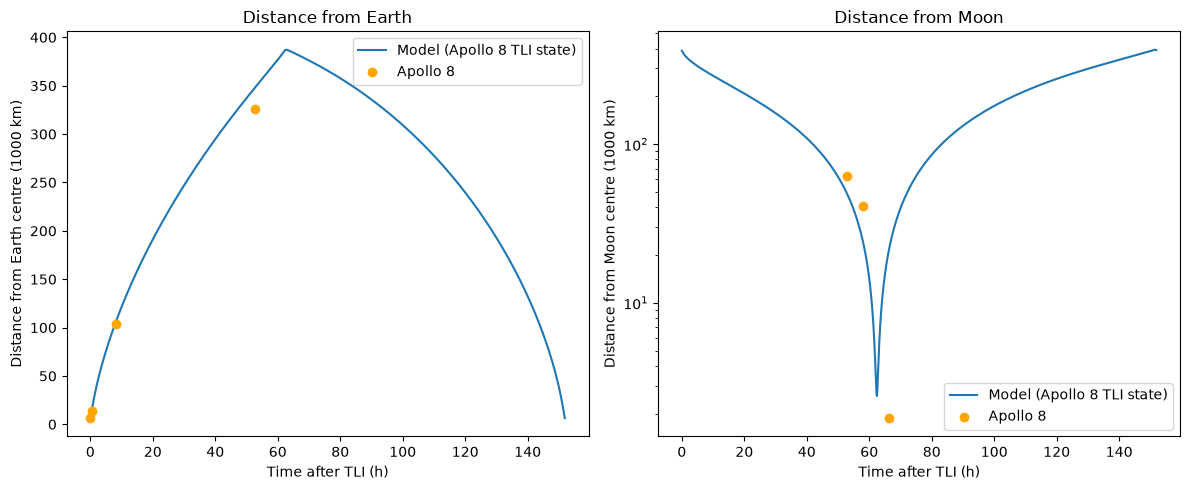

In [8]:
fig1 = plt.figure(figsize=(12, 5))
ax11 = fig1.add_subplot(121)
ax12 = fig1.add_subplot(122)

# stop the plots at entry interface
n_ei = ev_a8['ei_idx'] + 2
t_a8_h = times_a8[:n_ei] * T / 3600

ax11.plot(t_a8_h, earth_dist(u_a8[:n_ei])/1000, label='Model (Apollo 8 TLI state)')
ax11.scatter(apollo8_earth_dist[:, 0], apollo8_earth_dist[:, 1]/1000, color='ORANGE', zorder=3, label='Apollo 8')
ax11.set_title('Distance from Earth')
ax11.set_xlabel('Time after TLI (h)')
ax11.set_ylabel('Distance from Earth centre (1000 km)')
ax11.legend()

ax12.plot(t_a8_h, moon_dist(u_a8[:n_ei])/1000, label='Model (Apollo 8 TLI state)')
ax12.scatter(apollo8_moon_dist[:, 0], apollo8_moon_dist[:, 1]/1000, color='ORANGE', zorder=3, label='Apollo 8')
ax12.set_title('Distance from Moon')
ax12.set_xlabel('Time after TLI (h)')
ax12.set_ylabel('Distance from Moon centre (1000 km)')
ax12.set_yscale('log')
ax12.legend()

fig1.tight_layout()

Apollo 8's measured points only cover the outbound coast, because after LOI the real spacecraft stayed in lunar orbit for 20 hours and the model does not. The LOI point is plotted for reference but was reached after the midcourse correction had lowered the approach to ~66 n mi, so it sits below the model's uncorrected 458 n mi pass.

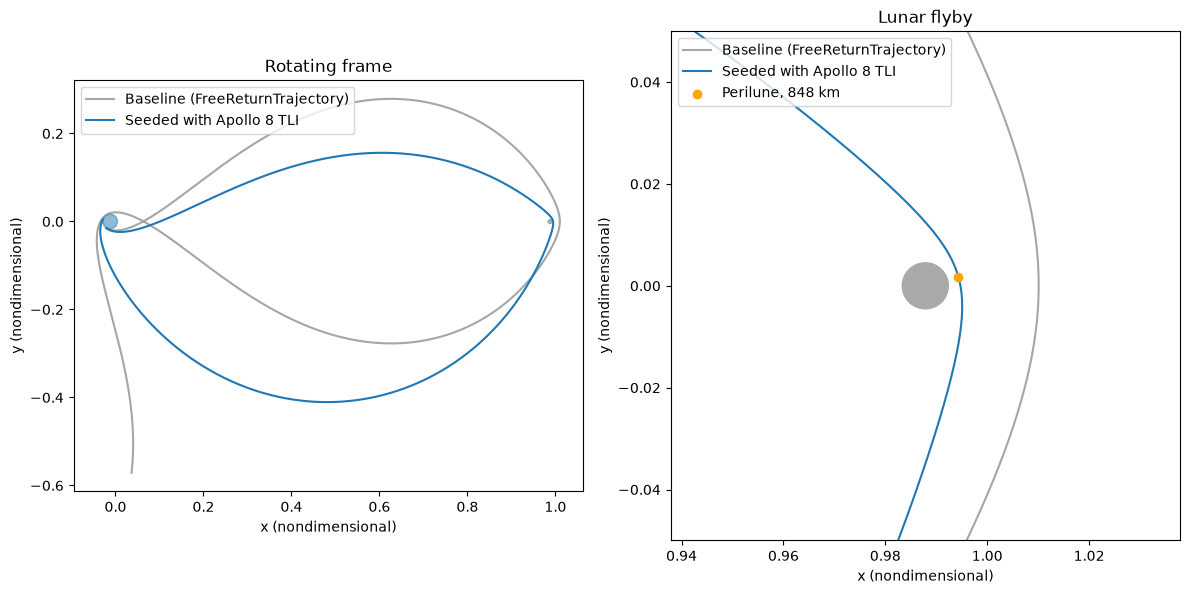

In [9]:
fig2 = plt.figure(figsize=(12, 6))
ax21 = fig2.add_subplot(121)
ax22 = fig2.add_subplot(122)

for ax in (ax21, ax22):
    ax.plot(u_base[:, 0], u_base[:, 1], label='Baseline (FreeReturnTrajectory)', color='GREY', alpha=0.7)
    ax.plot(u_a8[:n_ei, 0], u_a8[:n_ei, 1], label='Seeded with Apollo 8 TLI')
    ax.add_patch(plt.Circle((-MU, 0), R_EARTH/L, color='tab:blue', alpha=0.5))
    ax.add_patch(plt.Circle((1 - MU, 0), R_MOON/L, color='DARKGREY'))
    ax.set_aspect('equal')
    ax.set_xlabel('x (nondimensional)')
    ax.set_ylabel('y (nondimensional)')

ax21.set_title('Rotating frame')
ax21.legend(loc='upper left')

k = ev_a8['perilune_idx']
ax22.set_title('Lunar flyby')
ax22.set_xlim(1 - MU - 0.05, 1 - MU + 0.05)
ax22.set_ylim(-0.05, 0.05)
ax22.scatter(u_a8[k, 0], u_a8[k, 1], color='ORANGE', zorder=3, label=f'Perilune, {ev_a8["perilune_alt"]:.0f} km')
ax22.legend(loc='upper left')

fig2.tight_layout()

## Discussion

The useful check is that the time to the Moon, the time to get back to Earth, and the entry conditions all come *out of* the model: only the perilune altitude was used to choose $\phi$. Read the table above for the actual numbers. Where they disagree, the main causes are things the planar CR3BP leaves out:

- **Three dimensions.** Apollo 8's parking orbit was inclined 32.5° and the Moon's orbit is inclined about 5° to the ecliptic. The real trajectory was not in the Earth–Moon plane, so a planar model cannot match both the geometry and the timing exactly.
- **Circular lunar orbit.** The model holds the Moon at $L = 384{,}400$ km. The real Earth–Moon distance changes by about ±5% over a month, which directly changes the coast time.
- **Other forces.** The Sun's gravity, Earth's oblateness ($J_2$) and the real ephemeris are all left out. Over a 6-day trip these move the trajectory by tens to hundreds of km.
- **What the real data measures.** The entry speed and angle reported for Apollo 8 come from its actual return after transearth injection, not from an uncorrected free return. Both trajectories fall back from lunar distance, so entry speed should be very similar, but the timing is not directly comparable. That is why the press kit's *planned* free-return entry time (~136 h after liftoff) is used instead.
- **Targeting.** Real free-return trajectories are tuned so the return perigee lands inside a narrow entry corridor (around −6.5°). Here only perilune altitude was targeted, so the entry angle is a consequence and not a constraint.